# ChurnScope — exploration des données

Je cherche à comprendre quels profils de clients résilient le plus souvent, avant de construire un modèle prédictif. Les données viennent du jeu public IBM Telco Customer Churn. Ce notebook couvre le contrôle des données, le nettoyage et les premières visualisations ; l'entraînement et l'évaluation sont dans `src/train.py`.

Les écarts observés entre groupes sont des associations. Ils ne prouvent pas qu'un type de contrat ou de service cause la résiliation.

In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/raw/Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Afficher le nombre de lignes et colonnes

In [2]:
print("Nombre de lignes et colonnes :", df.shape)
print("\nColonnes disponibles :")
print(df.columns.tolist())

Nombre de lignes et colonnes : (7043, 21)

Colonnes disponibles :
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


Types des colonnes

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Contrôle de toutes les colonnes

Je vérifie les types, le nombre de modalités, les vraies valeurs nulles et les chaînes vides. Une chaîne contenant seulement un espace n'est pas comptée comme manquante par `df.info()` : c'est précisément le cas de `TotalCharges`.

In [4]:
audit_colonnes = pd.DataFrame([
    {
        'colonne': colonne,
        'type': str(df[colonne].dtype),
        'valeurs_distinctes': df[colonne].nunique(dropna=False),
        'nulles': df[colonne].isna().sum(),
        'chaines_vides': df[colonne].astype('string').str.strip().eq('').fillna(False).sum(),
    }
    for colonne in df.columns
])
display(audit_colonnes)
print('Identifiants en double :', df['customerID'].duplicated().sum())
print('Profils identiques hors identifiant :', df.drop(columns='customerID').duplicated().sum())

,colonne,type,valeurs_distinctes,nulles,chaines_vides
0,customerID,str,7043,0,0
1,gender,str,2,0,0
2,SeniorCitizen,int64,2,0,0
3,Partner,str,2,0,0
4,Dependents,str,2,0,0
5,tenure,int64,73,0,0
6,PhoneService,str,2,0,0
7,MultipleLines,str,3,0,0
8,InternetService,str,3,0,0
9,OnlineSecurity,str,3,0,0


Identifiants en double : 0
Profils identiques hors identifiant : 22


Les 22 profils identiques hors identifiant ne sont pas supprimés : deux clients distincts peuvent partager les mêmes caractéristiques. Je contrôle ensuite les modalités des colonnes catégorielles et la cohérence entre l'abonnement Internet/téléphone et les services associés.

In [5]:
colonnes_categorielles = [c for c in df.columns if df[c].nunique() <= 4 and c != 'customerID']
modalites = pd.DataFrame([
    {'colonne': c, 'modalites': ', '.join(map(str, df[c].unique()))}
    for c in colonnes_categorielles
])
display(modalites)
colonnes_internet = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                     'TechSupport', 'StreamingTV', 'StreamingMovies']
telephone_incoherent = (df['PhoneService'].eq('No') != df['MultipleLines'].eq('No phone service')).sum()
internet_incoherent = {c: (df['InternetService'].eq('No') != df[c].eq('No internet service')).sum()
                      for c in colonnes_internet}
print('Incohérences téléphone :', telephone_incoherent)
print('Incohérences Internet :', internet_incoherent)

,colonne,modalites
0,gender,"Female, Male"
1,SeniorCitizen,"0, 1"
2,Partner,"Yes, No"
3,Dependents,"No, Yes"
4,PhoneService,"No, Yes"
5,MultipleLines,"No phone service, No, Yes"
6,InternetService,"DSL, Fiber optic, No"
7,OnlineSecurity,"No, Yes, No internet service"
8,OnlineBackup,"Yes, No, No internet service"
9,DeviceProtection,"No, Yes, No internet service"


Incohérences téléphone : 0
Incohérences Internet : {'OnlineSecurity': np.int64(0), 'OnlineBackup': np.int64(0), 'DeviceProtection': np.int64(0), 'TechSupport': np.int64(0), 'StreamingTV': np.int64(0), 'StreamingMovies': np.int64(0)}


In [6]:
empty_total_charges = (df["TotalCharges"].str.strip() == "").sum()

print("Nombre de valeurs vides dans TotalCharges :", empty_total_charges)

Nombre de valeurs vides dans TotalCharges : 11


In [7]:
clients_sans_total = df[df["TotalCharges"].str.strip() == ""]

clients_sans_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Donc là haut les clients avec total charges null viennent de s'abonner cette valeur on peut la metrre a 0 
1. convertir `TotalCharges` en valeur numérique 
2. remplacer les valeurs vides des nouveaux clients par `0` 
3. vérifier qu’il ne reste aucune valeur manquante

In [8]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

assert df['TotalCharges'].isna().sum() == empty_total_charges
missing_charges = df['TotalCharges'].isna()
assert (missing_charges & df['tenure'].ne(0)).sum() == 0
df.loc[missing_charges, 'TotalCharges'] = 0

print("Type de TotalCharges :", df["TotalCharges"].dtype)
print("Valeurs manquantes :", df["TotalCharges"].isna().sum())

Type de TotalCharges : float64
Valeurs manquantes : 0


Après cette correction, je vérifie qu'aucune valeur ne manque, que les montants et l'ancienneté ne sont pas négatifs, et je regarde les plages des trois variables numériques. Je conserve les valeurs élevées observées : sans preuve d'erreur, les supprimer ferait perdre de l'information.

In [9]:
numeriques = ['tenure', 'MonthlyCharges', 'TotalCharges']
print('Valeurs manquantes restantes :', int(df.isna().sum().sum()))
print('Valeurs négatives :', {c: int(df[c].lt(0).sum()) for c in numeriques})
display(df[numeriques].describe().T[['min', '25%', '50%', '75%', 'max']])
assert df.isna().sum().sum() == 0
assert all(df[c].ge(0).all() for c in numeriques)

Valeurs manquantes restantes : 0
Valeurs négatives : {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}


,min,25%,50%,75%,max
tenure,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,18.25,35.50,70.35,89.85,118.75
TotalCharges,0.00,398.55,1394.55,3786.60,8684.80


## Répartition du churn
j'observe la proportion de clients ayant résilié ou non leur abonnement

In [10]:
churn_repartition = df["Churn"].value_counts(
    normalize=True
).mul(100).round(1)

print(churn_repartition)

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


## Répartition du churn et choix des métriques

Les données sont déséquilibrées :

- 73,5 % des clients restent 
- 26,5 % des clients résilient.

Dans ce contexte l’accuracy seule peut être trompeuse  
Un modèle qui prédit toujours qu’un client reste obtiendrait déjà 73,5 % d’accuracy, sans détecter aucun départ.

j'utilise donc l’accuracy en complément de :

- **Recall** : repérer le plus possible de clients qui vont résilier 
(parmi les clients qui partent vraiment, combien le modèle a réussi à repérer ? 
Un bon recall évite de laisser partir beaucoup de clients sans les détecter)

- **Precision** : éviter de signaler trop de clients qui ne partiront pas 
(parmi les clients que le modèle annonce comme « vont partir », combien partent vraiment ?
Une bonne precision évite de cibler inutilement des clients avec une offre de rétention)

- **AUC-ROC** : mesurer la capacité globale du modèle à distinguer les clients à risque.
(mesure globale de la capacité du modèle à distinguer les clients qui vont partir de ceux qui vont rester.  
- 0,5 : le modèle fait presque au hasard 
- 1,0 : il sépare parfaitement les deux groupes.
  Plus c’est proche de 1, mieux c’est)

## Churn selon le type de contrat
je compare le taux de résiliation selon le type de contrat du client.

In [11]:
churn_par_contrat = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(1)

print(churn_par_contrat)

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


### Interprétation

Le churn est beaucoup plus élevé pour les clients avec un contrat mensuel (42,7 %) que pour les contrats d’un an (11,3 %) ou deux ans (2,8 %).

Le type de contrat semble donc être une variable importante pour prédire la résiliation. Cette observation montre une association, mais ne prouve pas à elle seule que le contrat cause le départ.

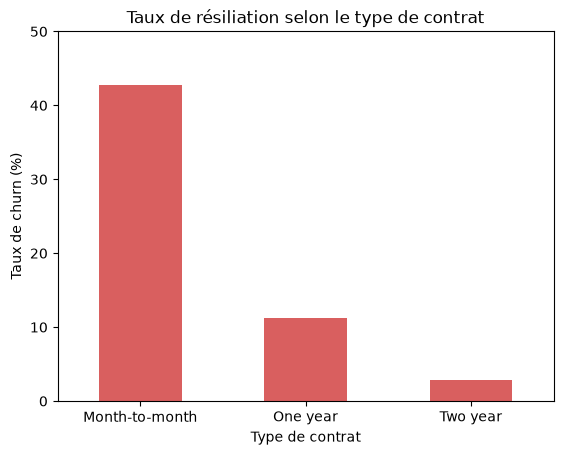

In [12]:
import matplotlib.pyplot as plt

churn_par_contrat["Yes"].sort_values(
    ascending=False
).plot(
    kind="bar",
    color="#d95f5f"
)

plt.title("Taux de résiliation selon le type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Taux de churn (%)")
plt.xticks(rotation=0)
plt.ylim(0, 50)
plt.show()

## Churn selon le service Internet
je compare le taux de résiliation entre les clients DSL, fibre optique et ceux qui n’ont pas de service Internet.

In [13]:
churn_par_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).mul(100).round(1)

print(churn_par_internet)

Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4


### Conclusion

Le churn est le plus élevé chez les clients ayant une connexion fibre optique (41,9 %).

Le type de service Internet semble donc être une variable pertinente pour prédire la résiliation.

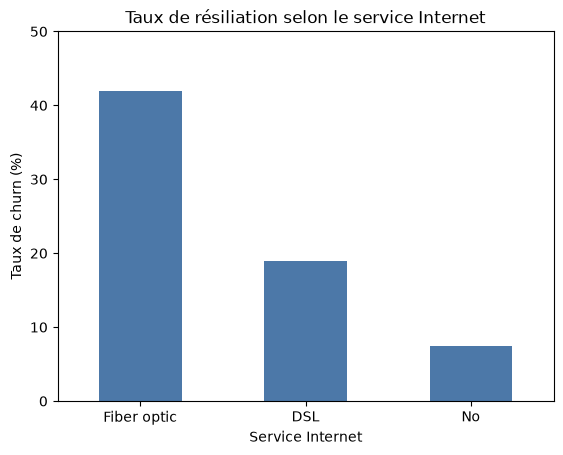

In [14]:
churn_par_internet["Yes"].sort_values(
    ascending=False
).plot(
    kind="bar",
    color="#4c78a8"
)

plt.title("Taux de résiliation selon le service Internet")
plt.xlabel("Service Internet")
plt.ylabel("Taux de churn (%)")
plt.xticks(rotation=0)
plt.ylim(0, 50)
plt.show()

## Churn selon l’ancienneté

je compare l’ancienneté des clients qui résilient avec celle des clients qui restent.

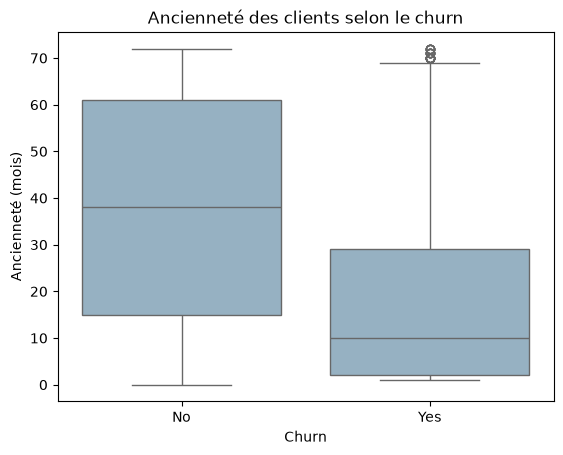

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    order=["No", "Yes"],
    color="#8fb3c9"
)

plt.title("Ancienneté des clients selon le churn")
plt.xlabel("Churn")
plt.ylabel("Ancienneté (mois)")
plt.show()

## Moyen de paiement et montant mensuel

Je regarde deux autres variables liées à la facturation. Le taux de résiliation est de 45,3 % pour les paiements par chèque électronique dans ces données, contre environ 15 à 19 % pour les autres modes. C'est une association : le mode de paiement peut aussi être lié au type de contrat ou à d'autres caractéristiques.

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.8,15.2
Electronic check,54.7,45.3
Mailed check,80.9,19.1


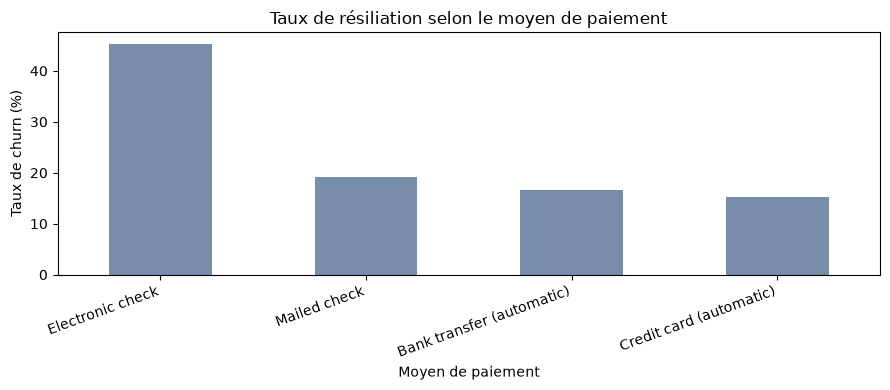

In [16]:
churn_par_paiement = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index').mul(100).round(1)
display(churn_par_paiement)
churn_par_paiement['Yes'].sort_values(ascending=False).plot(kind='bar', color='#778da9', figsize=(9, 4))
plt.title('Taux de résiliation selon le moyen de paiement')
plt.xlabel('Moyen de paiement')
plt.ylabel('Taux de churn (%)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

Le montant mensuel médian est de 79,65 pour les clients qui résilient et de 64,43 pour ceux qui restent. Le graphique permet aussi de voir le recouvrement entre les deux groupes : ce montant seul ne suffit pas à prédire un départ.

Médiane de MonthlyCharges par groupe :


Churn
No     64.43
Yes    79.65
Name: MonthlyCharges, dtype: float64

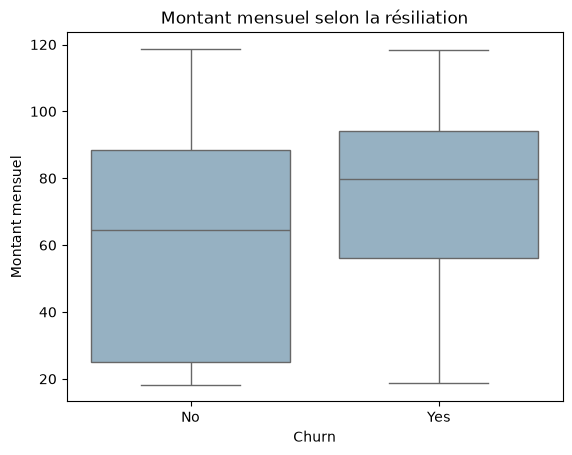

In [17]:
print('Médiane de MonthlyCharges par groupe :')
display(df.groupby('Churn')['MonthlyCharges'].median().round(2))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], color='#8fb3c9')
plt.title('Montant mensuel selon la résiliation')
plt.xlabel('Churn')
plt.ylabel('Montant mensuel')
plt.show()

## Ce que je retiens avant la modélisation

Les contrats mensuels présentent plus de résiliations que les contrats annuels ; la fibre et le paiement par chèque électronique sont aussi associés à des taux plus élevés. Les clients qui partent ont une ancienneté médiane de 10 mois contre 38 mois pour ceux qui restent, et un montant mensuel médian plus élevé. Ces observations m'aident à formuler des hypothèses, mais ne permettent pas d'établir des causes.

La cible est déséquilibrée : environ 26,5 % des clients résilient. Un modèle qui répond toujours « reste » aurait déjà près de 73,5 % d'accuracy, mais ne détecterait aucun départ. Dans `src/train.py`, je compare donc les modèles avec une validation croisée sur l'entraînement, puis je vérifie le modèle retenu une seule fois sur un jeu de test conservé à part. Le rappel, la précision et la courbe précision-rappel complètent l'accuracy et le ROC-AUC.